# 3.3.- Evaluación de Modelos de Clasificación

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, roc_curve, roc_auc_score,
    accuracy_score, precision_score, recall_score,
    f1_score, matthews_corrcoef
)

## Carga de datos y entrenamiento del modelo

Usaremos el dataset **Breast Cancer** incluido en `scikit-learn`.  
- Contiene medidas de características de células tumorales.  
- Objetivo: predecir si un tumor es **benigno (0)** o **maligno (1)**.  

Entrenaremos un **modelo de Regresión Logística** como clasificador base.

* Como en el dataset original **benigno=1** y **maligno=0**, se invierten los **1** y **0** para que sea mas fácil de comprender.

In [8]:
# Cargar dataset
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(1 - data.target)  # Invertir: 1 → 0 y 0 → 1

# División train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=33)

# Escalado
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Entrenar modelo
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)

print("Modelo entrenado correctamente.")

Modelo entrenado correctamente.


## Matriz de confusión y métricas de clasificación

Una vez entrenado el modelo, evaluamos su rendimiento en el conjunto de **test**.  

- **Matriz de confusión**: muestra los aciertos y errores de clasificación.  
- **Métricas clave**: Accuracy, Precision, Recall, F1-score y MCC.  
Estas nos ayudan a entender mejor el rendimiento que un simple porcentaje de aciertos.

* Se invierte el array de nombres de clases **data.target_names[::-1]**, porque en el dataset original **benigno=1** y **maligno=0**. 

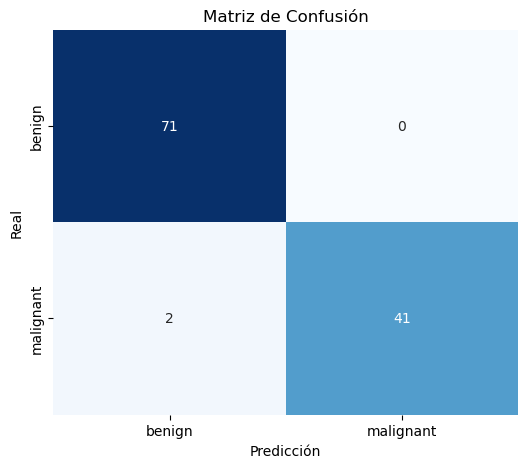

Accuracy: 0.9824561403508771
Precision: 1.0
Recall: 0.9534883720930233
F1-score: 0.9761904761904762
MCC: 0.962998132394131


In [11]:
# Predicciones directas con umbral 0.5
y_pred = model.predict(X_test_scaled)

# Matriz de confusión
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=data.target_names[::-1], yticklabels=data.target_names[::-1])
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title("Matriz de Confusión")
plt.show()

# Cálculo de métricas
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
mcc = matthews_corrcoef(y_test, y_pred)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)
print("MCC:", mcc)

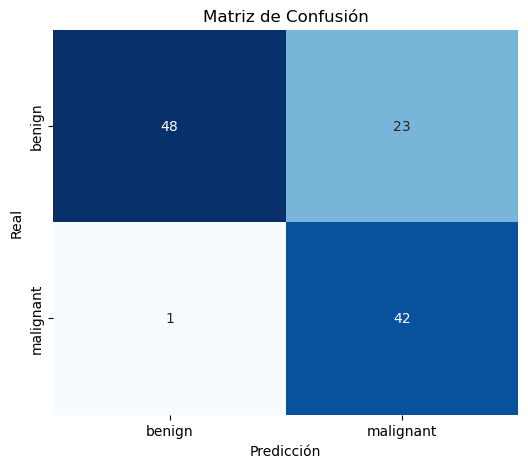

Accuracy: 0.7894736842105263
Precision: 0.6461538461538462
Recall: 0.9767441860465116
F1-score: 0.7777777777777778
MCC: 0.6391299630960106


In [18]:
# Probabilidades de la clase positiva
y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]

# Clasificación con umbral
umbral = 0.01
y_pred = (y_pred_proba >= umbral).astype(int)

# Matriz de confusión
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=data.target_names[::-1], yticklabels=data.target_names[::-1])
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title("Matriz de Confusión")
plt.show()

# Cálculo de métricas
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
mcc = matthews_corrcoef(y_test, y_pred)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)
print("MCC:", mcc)

## Curva ROC y AUC

La **Curva ROC** (Receiver Operating Characteristic) muestra el compromiso entre:

- **TPR (Recall o Sensibilidad)**: proporción de positivos reales correctamente identificados.  
- **FPR (Tasa de Falsos Positivos)**: proporción de negativos clasificados erróneamente como positivos.  

El **AUC (Área Bajo la Curva)** resume esta curva en un solo valor:
- 0.5 → rendimiento aleatorio.
- 1.0 → clasificador perfecto.

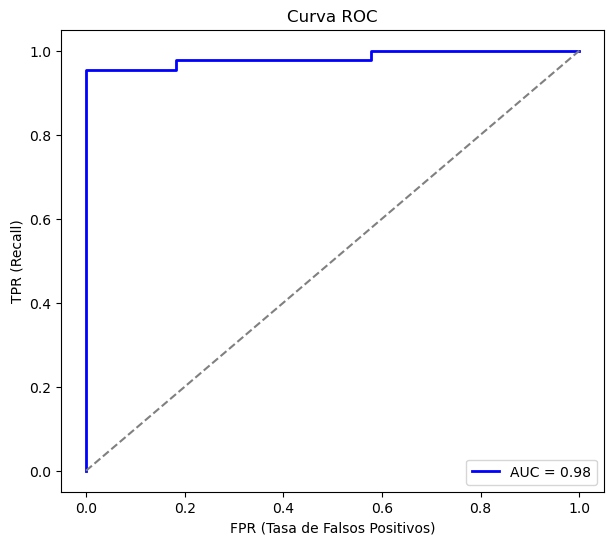

In [10]:
# Probabilidades de la clase positiva
y_scores = model.predict_proba(X_test_scaled)[:,1]

# Calcular curvas ROC
fpr, tpr, thresholds = roc_curve(y_test, y_scores)
auc = roc_auc_score(y_test, y_scores)

# Dibujar curva ROC
plt.figure(figsize=(7,6))
plt.plot(fpr, tpr, color="blue", lw=2, label=f"AUC = {auc:.2f}")
plt.plot([0,1], [0,1], linestyle="--", color="gray")  # línea aleatoria
plt.xlabel("FPR (Tasa de Falsos Positivos)")
plt.ylabel("TPR (Recall)")
plt.title("Curva ROC")
plt.legend(loc="lower right")
plt.show()